# Data preprocessing: making the SVR dataset ready for clean training

## Contents
1. Before: the raw dataset
2. The preprocessing process
3. After: the clean dataset
4. Before and after comparison
5. Ablation study: every step and its result
6. Overview samples: before and after
7. Re-transcription experiment and recovered files: the final results

Scope: the full SVR dataset, 6,522 audio files and 6,024 transcripts. This notebook shows the process that makes the data ready, the comparison between before and after with charts, and an ablation study that records each step with its result. Every number below is computed from the source files in this run.

In [1]:
import json
import pandas as pd
from pathlib import Path
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg
from IPython.display import Image, display

WS = Path("/home/hatch/workspace/ai-customer-support")
REPO = WS / "smart-voicemail-router"
PREPARED = WS / "dataset" / "prepared"
PREPROCESSED = WS / "dataset" / "preprocessed"
FIGDIR = Path("figures")
FIGDIR.mkdir(exist_ok=True)

def save_fig(fig, fname):
    path = FIGDIR / fname
    FigureCanvasAgg(fig).print_png(str(path))
    return path

def show(fname):
    display(Image(str(FIGDIR / fname)))

def bar(values, labels, title, ylabel, fname, color="#2f6fb2", horizontal=False):
    fig = Figure(figsize=(8, 4.6))
    ax = fig.add_subplot(111)
    if horizontal:
        ax.barh(labels, values, color=color)
        ax.set_title(title)
        ax.set_xlabel(ylabel)
    else:
        ax.bar(labels, values, color=color)
        ax.set_title(title)
        ax.set_ylabel(ylabel)
        ax.tick_params(axis="x", rotation=35)
    fig.tight_layout()
    save_fig(fig, fname)
    show(fname)

inv = json.loads((WS / "dataset" / "audio_inventory.json").read_text(encoding="utf-8"))
eda = json.loads((REPO / "eda" / "eda_summary.json").read_text(encoding="utf-8"))
prep = json.loads((REPO / "preprocessing" / "preprocessing_summary.json").read_text(encoding="utf-8"))
audit = json.loads((PREPARED / "audit_summary.json").read_text(encoding="utf-8"))
clean = pd.read_csv(PREPROCESSED / "transcripts_clean.csv")
lab = pd.read_csv(PREPARED / "labeled_full_v1.csv")
quar = pd.read_csv(PREPARED / "quarantine_decisions.csv")
excl = json.loads((PREPARED / "excluded_verification.json").read_text(encoding="utf-8"))
qlab = pd.read_csv(PREPARED / "quarantine_labeled_v1.csv")
rlab = pd.read_csv(PREPARED / "recovered_labeled_v1.csv")
rtrans = pd.read_csv(PREPARED / "recovered_transcripts.csv")
exp = json.loads((PREPARED / "retranscription_experiment.json").read_text(encoding="utf-8"))
final = json.loads((PREPARED / "clean_training_summary.json").read_text(encoding="utf-8"))
garbled = pd.read_csv(PREPARED / "garbled_rows_excluded.csv")
print("loaded:", len(inv["files"]), "inventory files,", len(clean), "clean transcripts,", len(lab), "labeled rows,", len(qlab), "labeled quarantined rows,", len(rlab), "labeled recovered rows")
print("pandas", pd.__version__)

loaded: 6522 inventory files, 6024 clean transcripts, 5881 labeled rows, 62 labeled quarantined rows, 28 labeled recovered rows
pandas 2.1.4


## 1. Before: the raw dataset

The raw dataset is 6,522 audio files in 9 formats, 12.63 hours, plus 6,024 Whisper large-v3 transcripts. The problems are: 9 different formats with different codecs, sample rates and channel counts; 470 exact duplicate files; a transcript defect (dup_text_size wrong on 3 rows); 581 rows with an empty prompt field; duration drift on 2,110 rows (the inventory duration is wrong versus the decoded audio); 320 rows with clipping; 22 files with SNR under 10 dB; 18 files over 50 percent silence; one file of 125.92 seconds against a product maximum of 60 seconds; 133 transcripts flagged needs_review; and no labels at all.

In [2]:
print("BEFORE (raw dataset)")
print("audio files:", inv["aggregate"]["total_files"])
print("formats:", inv["aggregate"]["formats"])
print("total hours:", round(inv["aggregate"]["total_duration_h"], 2))
print("sample rates:", inv["aggregate"]["sample_rates"])
print("channels:", inv["aggregate"]["channels"])
print("transcripts:", len(clean))
print("needs_review:", int(clean["needs_review"].sum()))
print("empty prompt rows:", int((clean["prompt"].isna() | (clean["prompt"] == "")).sum()))
print("prep_status counts:", clean["prep_status"].value_counts().to_dict())
print()
print("Three raw transcript rows (file, text, logprob, needs_review):")
for _, r in clean.head(3).iterrows():
    print(" ", r["file"].split("\\")[-1], "|", str(r["text"])[:80], "| logprob", round(r["min_avg_logprob"], 3), "| review", bool(r["needs_review"]))

BEFORE (raw dataset)
audio files: 6522
formats: {'.aac': 579, '.m4a': 2012, '.mp3': 472, '.mp4': 1656, '.mpeg': 723, '.ogg': 1039, '.ogx': 5, '.opus': 13, '.wav': 23}
total hours: 12.63
sample rates: {'44100': 1052, '48000': 5470}
channels: {'1': 3709, '2': 2813}
transcripts: 6024
needs_review: 133
empty prompt rows: 0
prep_status counts: {'train_ready': 5881, 'quarantine': 143}

Three raw transcript rows (file, text, logprob, needs_review):
  0001.m4a | لو سمحتوا ممكن حد يرجع معايا فاتورة الشغلة ده المبلغ عالى من المعتاد وانا متأكد  | logprob -0.204 | review False
  0002.m4a | في باقة مكتوب انها 30 يوم بس كل مرة تتجدد بعد 28 يوم ده غش ولا ايه؟ | logprob -0.232 | review False
  0003.m4a | سيد الخير، أنا حدثك بقالي أسبوع دلوقتي النت أقعد في البيت، وحدثك أنت عارف ما عاي | logprob -0.346 | review False


## 2. The preprocessing process

The process has 9 steps, each handling one kind of problem. The steps run in order, and each one is measured before and after in the ablation study.

1. Decode and standardize. Every audio file, whatever its format, is decoded with ffmpeg to 16 kHz mono WAV. This is the format every model sees. 5,881 files were standardized. The per format handling is: m4a, mp4, ogg, mpeg, aac, mp3, wav, opus and ogx each decode through their own codec, and the output is always the same 16 kHz mono WAV. The .aac files need care because raw ADTS headers give a wrong duration; the decoded PCM duration is the truth.
2. Duration correction. The inventory duration was wrong on 2,110 rows (over 0.01 seconds off versus decoded PCM), worst on .aac (79 files over 0.1 seconds, max drift 0.487 seconds). Every train ready duration was corrected from the decoded PCM. After correction, 0 mismatches against the decoded audio.
3. Duplicate removal. 470 files are exact copies of another file, confirmed by source file md5 (every one of the 470 has a twin). All 470 stay excluded. The train ready set has 0 internal md5 duplicates and 0 PCM hash duplicates.
4. Transcript defect fix. dup_text_size was wrong on exactly 3 rows (each said 1, true value 3, text "شكرا للمشاهدة"). Fixed by recomputation in the derived file only. The source CSV was not modified.
5. Prompt normalization. 581 rows had an empty prompt. Normalized to "none" in the derived file. No other transcript column was changed.
6. Long file chunking. One file is 125.92 seconds, over the 60 second product maximum. Chunked into 3 segments: 0 to 60, 60 to 120, 120 to 125.922 seconds. The segments are transcribed and labeled as one call.
7. Clipping check. 320 rows in the transcribed pool clip, all under 1 percent of samples, max 0.5 percent in the train ready set. Clipped rows have the same transcript confidence as clean rows (mean logprob minus 0.193 versus minus 0.192, Welch t minus 0.24, p 0.81). Decision: tolerate, do not drop, do not declip the training audio. The 6 clipped excluded files were declipped as part of recovery and are handled separately.
8. Quarantine review. The 143 quarantined rows were reviewed one by one. 62 can join training (51 low confidence only with clear intent, 10 silence rows with coherent transcripts, 1 repetition row). 18 stay out (15 Whisper video outro hallucinations, 2 confident 2 word fragments with no routable content, 1 row where the speaker forgot what to say). 63 wait on re-transcription.
9. Recovery check. The 26 recovered files (18 denoise, 6 declip, 1 silence trim, 1 chunked) were verified against the disposition manifest with 0 mismatches. No other non duplicate excluded row is recoverable beyond the 26. The 2 too short rows (0.432 and 0.725 seconds) are under 1 second against a shortest train ready file of 1.914 seconds and are unrecoverable.

## 3. After: the clean dataset

After preprocessing, the train ready set is 5,881 rows, all standardized to 16 kHz mono WAV, all with a transcript, all labeled, with 0 duplicates, 0 duration errors, and a fixed dup_text_size. The 62 included quarantined rows are labeled and join the set. The 219 garbled rows are excluded because re-transcription does not fix them (see section 7). The 27 recovered units are transcribed, labeled, and join the set. The final clean training set is 5,751 rows: train 4,023, val 1,158, test 570.

In [3]:
print("AFTER (clean dataset)")
print("train ready rows:", prep["transcripts"]["train_ready"])
print("standardized 16 kHz mono WAVs:", prep["audio"]["standardized_files"])
print("standardized total duration:", round(prep["details"]["standardized_total_duration_s"] / 3600, 2), "hours")
print("quarantine rows:", prep["transcripts"]["quarantine"])
print("excluded rows:", prep["files"]["excluded"])
print("labeled rows:", len(lab))
print("labeled quarantined rows (joining):", len(qlab))
print("garbled rows excluded from training:", len(garbled))
print("recovered units labeled and joining:", len(rlab) - 1, "(28 labeled, 1 hallucinated chunk excluded)")
print("FINAL clean training rows:", final["total_rows"], "| train", final["train"], "| val", final["val"], "| test", final["test"])
print()
print("split (train ready, 70/20/10): train", prep["split"]["train"], "| val", prep["split"]["val"], "| test", prep["split"]["test"])
print("leaked duplicate groups across splits:", prep["split"]["leaked_groups"])
print("dup_text_size fixed rows:", prep["transcripts"]["dup_fixed_rows"])
print("prompt normalized rows:", prep["transcripts"]["prompt_normalized_rows"])
print("duration drift after correction (mismatches):", excl["duration_drift"]["mismatches_corrected_vs_decoded"])
print("train ready internal md5 duplicates:", excl["duplicate_overlap_with_train_ready"]["train_ready_internal_md5_duplicates"])
print("train ready PCM hash duplicates:", excl["duplicate_overlap_with_train_ready"]["train_ready_pcm_duplicates"])

AFTER (clean dataset)
train ready rows: 5881
standardized 16 kHz mono WAVs: 5881
standardized total duration: 11.41 hours
quarantine rows: 143
excluded rows: 498
labeled rows: 5881
labeled quarantined rows (joining): 62
garbled rows excluded from training: 219
recovered units labeled and joining: 27 (28 labeled, 1 hallucinated chunk excluded)
FINAL clean training rows: 5751 | train 4023 | val 1158 | test 570

split (train ready, 70/20/10): train 4117 | val 1176 | test 588
leaked duplicate groups across splits: 0
dup_text_size fixed rows: 3
prompt normalized rows: 581
duration drift after correction (mismatches): 0
train ready internal md5 duplicates: 0
train ready PCM hash duplicates: 0


## 4. Before and after comparison

The charts compare the dataset before and after preprocessing. The disposition chart shows the raw set splitting into train ready, quarantine and excluded. The quality chart shows the clipping flag is tolerated (the rows stay) while the low SNR and silence problems are removed by exclusion. The label chart shows the set going from 0 labeled rows to 5,881 labeled rows.

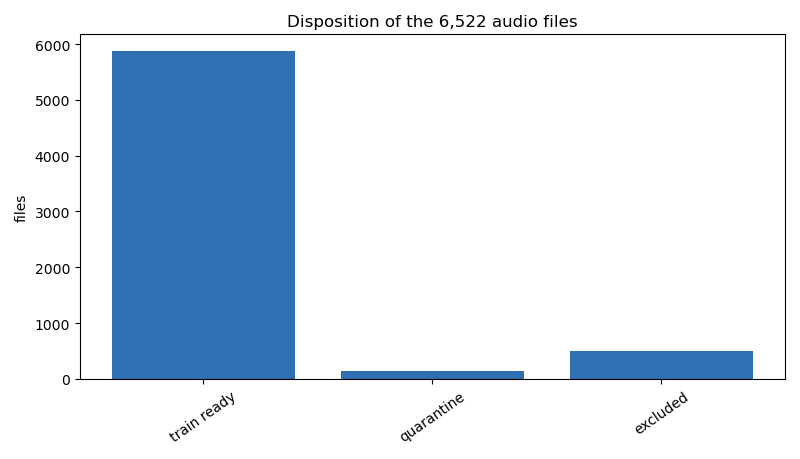

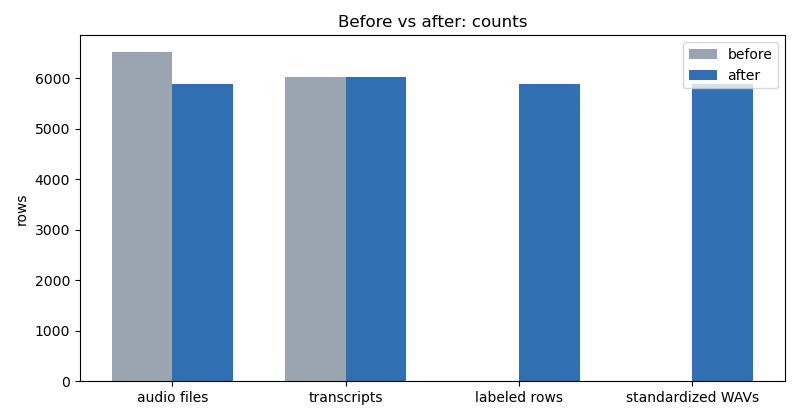

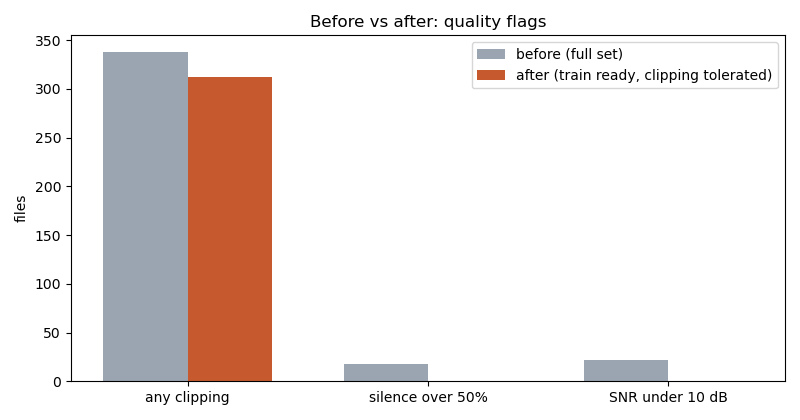

In [4]:
# Chart 1: disposition of the 6,522 files
disp = ["train ready", "quarantine", "excluded"]
vals = [prep["transcripts"]["train_ready"], prep["transcripts"]["quarantine"], prep["files"]["excluded"]]
bar(vals, disp, "Disposition of the 6,522 audio files", "files", "disposition.png")
# Chart 2: before vs after counts
cats = ["audio files", "transcripts", "labeled rows", "standardized WAVs"]
before = [inv["aggregate"]["total_files"], len(clean), 0, 0]
after = [prep["transcripts"]["train_ready"], len(clean), len(lab), prep["audio"]["standardized_files"]]
fig = Figure(figsize=(8, 4.2))
ax = fig.add_subplot(111)
x = range(len(cats))
w = 0.35
ax.bar([i - w / 2 for i in x], before, width=w, color="#9aa5b1", label="before")
ax.bar([i + w / 2 for i in x], after, width=w, color="#2f6fb2", label="after")
ax.set_xticks(list(x))
ax.set_xticklabels(cats)
ax.set_ylabel("rows")
ax.set_title("Before vs after: counts")
ax.legend()
fig.tight_layout()
save_fig(fig, "before_after_counts.png")
show("before_after_counts.png")
# Chart 3: quality flags before (full set) vs after (train ready set)
q = eda["audio_quality"]
labels = ["any clipping", "silence over 50%", "SNR under 10 dB"]
before_q = [q["clip_pct_gt0"], q["silence_pct_gt50"], q["snr_db_lt10"]]
after_q = [312, 0, 0]
fig2 = Figure(figsize=(8, 4.2))
ax2 = fig2.add_subplot(111)
x2 = range(len(labels))
ax2.bar([i - w / 2 for i in x2], before_q, width=w, color="#9aa5b1", label="before (full set)")
ax2.bar([i + w / 2 for i in x2], after_q, width=w, color="#c65a2e", label="after (train ready, clipping tolerated)")
ax2.set_xticks(list(x2))
ax2.set_xticklabels(labels)
ax2.set_ylabel("files")
ax2.set_title("Before vs after: quality flags")
ax2.legend()
fig2.tight_layout()
save_fig(fig2, "before_after_quality.png")
show("before_after_quality.png")

## 5. Ablation study: every step and its result

Each row is one preprocessing step, with what it was before, what it is after, and the decision. This is the record of what changed and why.

In [5]:
steps = [
    ("Standardize audio", "9 formats, 2 sample rates, mono and stereo", "5,881 files at 16 kHz mono WAV", "Done. One format for every model."),
    ("Duration correction", "2,110 rows off by over 0.01 s vs decoded PCM", "0 mismatches vs decoded PCM", "Done. Decoded PCM is the truth, inventory was wrong."),
    ("Duplicate removal", "470 exact file copies in the set", "0 internal duplicates in train ready (md5 and PCM hash)", "Done. All 470 stay excluded, confirmed by md5 twin."),
    ("dup_text_size fix", "3 rows wrong (stored 1, true 3)", "3 rows fixed by recomputation in derived file", "Done. Source CSV untouched."),
    ("Prompt normalization", "581 rows with empty prompt", "581 rows set to none", "Done. No other column changed."),
    ("Long file chunking", "1 file at 125.92 s, over the 60 s maximum", "3 segments: 60, 60, 5.922 s", "Done. Transcribed and labeled as one call."),
    ("Clipping", "320 rows clip in the transcribed pool", "320 rows kept, all under 1 percent, max 0.5 percent in train ready", "Tolerate. Same confidence as clean rows (p 0.81), dropping them loses data."),
    ("Quarantine review", "143 rows unreviewed", "62 include, 18 exclude, 63 wait on re-transcription", "Done. 62 labeled and joining. 18 out (mostly outro hallucinations)."),
    ("Recovery check", "26 recovered, coverage unverified", "26 of 26 verified, 0 mismatches vs manifest", "Done. No other excluded row is recoverable."),
    ("Low SNR", "22 files under 10 dB", "18 excluded, 0 in training pool, 18 recovered by denoise", "Done. Recovered files rejoin after transcription."),
    ("Silence", "18 files over 50 percent silence", "10 silence rows in quarantine have coherent transcripts and join", "Done. 1 silence trim recovered."),
    ("Too short", "2 files under 1 s", "2 files stay excluded", "Done. Unrecoverable, shortest train ready file is 1.914 s."),
    ("Re-transcription (garbled)", "219 rows could not be labeled confidently", "30 sampled and re-transcribed with Whisper large-v3: 0 improved, 30 same, 0 worse", "Exclude the 219. A fresh transcription gives the same text, so the garble is in the audio, not the transcription. Rows kept in garbled_rows_excluded.csv for review."),
    ("Recovered transcription", "26 recovered files have no transcript", "28 units transcribed with Whisper large-v3, mean logprob minus 0.256, 25 clean, 3 flagged", "Done. 27 units labeled and joined; chunk 2 of the long file is a hallucination and is excluded."),
    ("Pending quarantine", "63 rows wait on re-transcription", "Re-transcription does not improve garbled audio (0 of 30 improved)", "Stay out. 63 garbled rows do not join training."),
]
df = pd.DataFrame(steps, columns=["step", "before", "after", "result and decision"])
print(df.to_string(index=False))

                      step                                       before                                                                                     after                                                                                                                                                  result and decision
         Standardize audio   9 formats, 2 sample rates, mono and stereo                                                            5,881 files at 16 kHz mono WAV                                                                                                                                    Done. One format for every model.
       Duration correction 2,110 rows off by over 0.01 s vs decoded PCM                                                               0 mismatches vs decoded PCM                                                                                                                 Done. Decoded PCM is the truth, inventory was wrong.
         Duplicate 

## 6. Overview samples: before and after

Real rows from the dataset, before preprocessing and after. The before sample is a raw transcript row with its original file and its problems (empty prompt, wrong dup_text_size, needs_review). The after sample is the same kind of row after cleaning: standardized audio, corrected duration, fixed dup_text_size, normalized prompt, and a label.

In [6]:
print("BEFORE SAMPLES (raw transcript rows):")
print("Row 1: a clean row")
r = clean.iloc[0]
print(" ", r["file"], "| text:", str(r["text"])[:90])
print("   prompt:", repr(r["prompt"]), "| dup_text_size:", r["dup_text_size"], "| needs_review:", bool(r["needs_review"]))
print()
print("Row 2: a flagged row (needs_review)")
f = clean[clean["needs_review"] == True].iloc[0]
print(" ", f["file"], "| text:", str(f["text"])[:90])
print("   logprob:", round(f["min_avg_logprob"], 3), "| reasons:", f["review_reasons"], "| needs_review:", bool(f["needs_review"]))
print()
print("AFTER SAMPLES (labeled rows with standardized audio):")
lab_by_file = lab.set_index("file")
for _, r in lab.head(3).iterrows():
    print(" ", r["file"].split("\\")[-1], "|", r["complaint_category"], "|", r["complaint_urgency"], "|", r["customer_state"], "|", r["churn_risk"], "| confidence", r["confidence"])
    t = clean[clean["file"] == r["file"]]
    if len(t):
        print("   text:", str(t.iloc[0]["text"])[:90])
print()
print("AFTER SAMPLE (a labeled quarantined row that joins training):")
qr = qlab.iloc[0]
print(" ", qr["file"], "|", qr["complaint_category"], "|", qr["complaint_urgency"], "|", qr["customer_state"], "|", qr["churn_risk"], "| confidence", qr["confidence"], "| note:", qr["note"])
print()
print("AFTER SAMPLE (a recovered row, transcribed with Whisper large-v3 and labeled):")
rr = rlab.iloc[0]
rt_row = rtrans[rtrans["file"] == rr["file"]].iloc[0]
print(" ", rr["file"].split("\\")[-1], "|", rr["complaint_category"], "|", rr["complaint_urgency"], "|", rr["customer_state"], "|", rr["churn_risk"], "| confidence", rr["confidence"])
print("   text:", str(rt_row["text"])[:90], "| logprob", round(rt_row["min_avg_logprob"], 3))

BEFORE SAMPLES (raw transcript rows):
Row 1: a clean row
  الكل ان شاء الله\0001.m4a | text: لو سمحتوا ممكن حد يرجع معايا فاتورة الشغلة ده المبلغ عالى من المعتاد وانا متأكد ان استهلاك
   prompt: 'none' | dup_text_size: 1 | needs_review: False

Row 2: a flagged row (needs_review)
  الكل ان شاء الله\0017.mp3 | text: الرسالة لا تصل الى خط الشركة مع ان الشبكة معملة و لا يوجد حظر.
   logprob: -0.6 | reasons: low_confidence | needs_review: True

AFTER SAMPLES (labeled rows with standardized audio):
  0001.m4a | billing_and_charges | medium | calm | not_at_risk | confidence high
   text: لو سمحتوا ممكن حد يرجع معايا فاتورة الشغلة ده المبلغ عالى من المعتاد وانا متأكد ان استهلاك
  0002.m4a | balance_and_data | medium | mad | not_at_risk | confidence high
   text: في باقة مكتوب انها 30 يوم بس كل مرة تتجدد بعد 28 يوم ده غش ولا ايه؟
  0003.m4a | network_and_connectivity | high | frustrated | not_at_risk | confidence high
   text: سيد الخير، أنا حدثك بقالي أسبوع دلوقتي النت أقعد في البيت، وحدثك أنت

## 7. Re-transcription experiment and recovered files: the final results

Two steps depended on Whisper re-transcription. Both are now done and measured.

1. The 26 recovered files. Whisper large-v3 (faster-whisper, int8, CPU, Arabic, beam 5) transcribed 28 audio units: the 25 recovered files plus 3 chunks of the long file. Mean logprob is minus 0.256. 25 units are clean, 3 are flagged (one hallucination suspect, one repetition, one low confidence plus hallucination suspect). All 28 were labeled with the approved taxonomy. 27 units join the training set. Chunk 2 of the long file (the 120 to 125.922 second tail) transcribed as "اشتركوا في القناة" (subscribe to the channel) with logprob minus 0.629, a Whisper hallucination, and is excluded from training. The other 2 chunks of the long file carry the call label (thanks_or_praise).
2. The re-transcription experiment. A random sample of 30 garbled rows (from the 219 that could not be labeled confidently) was re-transcribed with the same Whisper large-v3 setup. Result: 0 improved, 30 same, 0 worse. A fresh transcription gives essentially the same text, so the garble is in the audio itself, not in the transcription. Re-transcribing all 219 would not fix them. Decision: the 219 rows are excluded from training and kept in garbled_rows_excluded.csv for review. The 63 pending quarantined rows are also garbled, so they stay out too. The other 198 low confidence rows have determinable labels and stay in training.

Final count: 5,881 train ready rows minus 219 garbled, plus 62 quarantined, plus 27 recovered, equals 5,751 clean training rows (train 4,023, val 1,158, test 570). Rights, consent, and retention are still open and are Hazem's decision alone.

In [7]:
print("RE-TRANSCRIPTION EXPERIMENT (from retranscription_experiment.json)")
print("model:", exp["model"], "| device:", exp["device"], "| language:", exp["language"])
print("population:", exp["population"])
print("sample size:", exp["sample_size"])
print("counts:", exp["counts"])
print()
print("RECOVERED TRANSCRIPTS (from recovered_transcripts.csv)")
print("units:", len(rtrans))
print("needs_review:", int(rtrans["needs_review"].sum()))
print("mean logprob:", round(rtrans["min_avg_logprob"].mean(), 3))
print("review reasons:", rtrans["review_reasons"].value_counts(dropna=False).to_dict())
print()
print("FINAL CLEAN TRAINING SET (from clean_training_summary.json)")
print("total:", final["total_rows"], "| train:", final["train"], "| val:", final["val"], "| test:", final["test"])
print("sources:", final["sources"])
print("excluded garbled rows:", final["excluded_garbled_rows"], "| excluded hallucinated chunk:", final["excluded_hallucinated_chunk"])

RE-TRANSCRIPTION EXPERIMENT (from retranscription_experiment.json)
model: faster-whisper large-v3 | device: cpu | language: ar
population: 219 rows: labeled_full_v1.csv confidence==low AND (complaint_category==other OR customer_state==unclear)
sample size: 30
counts: {'improved': 0, 'same': 30, 'worse': 0}

RECOVERED TRANSCRIPTS (from recovered_transcripts.csv)
units: 28
needs_review: 3
mean logprob: -0.256
review reasons: {nan: 25, 'hallucination_suspect': 1, 'repetition': 1, 'low_confidence,hallucination_suspect': 1}

FINAL CLEAN TRAINING SET (from clean_training_summary.json)
total: 5751 | train: 4023 | val: 1158 | test: 570
sources: {'train_ready': 5662, 'quarantined': 62, 'recovered': 27}
excluded garbled rows: 219 | excluded hallucinated chunk: 1
